# Assignment 1: End-to-End Machine Learning Pipeline
**EMEA AI Cohort 12 — Hands-on Assignment**

## Objective
Build a complete binary-classification pipeline using a dataset from the UCI Machine Learning Repository. This notebook covers data inspection, cleaning, missing-value handling, categorical encoding, feature scaling, model training, evaluation, visualizations, and a conclusion based on the results produced when the notebook is run.

**Dataset:** Adult (Census Income) dataset from UCI.  
**Prediction target:** Whether annual income is greater than $50,000 (`>50K`) or not (`<=50K`).  
**Model:** Logistic Regression.

> **Important:** The notebook does not hard-code or invent performance results. Run all cells in order; the metrics and plots will be generated from the downloaded dataset and trained model.

In [1]:
%pip install -q ucimlrepo pandas numpy scikit-learn matplotlib seaborn

In [27]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme()
print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
adult = fetch_ucirepo(id=2)

X_raw = adult.data.features.copy()
y_raw = adult.data.targets.copy()

print("Feature data shape:", X_raw.shape)
print("Target data shape:", y_raw.shape)
display(X_raw.head())
display(y_raw.head())

Feature data shape: (48842, 14)
Target data shape: (48842, 1)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


,income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K


In [5]:

X = X_raw.copy()
X.columns = [str(col).strip().replace("-", "_").replace(" ", "_") for col in X.columns]


for col in X.columns:
    if X[col].dtype == "object" or pd.api.types.is_string_dtype(X[col]):
        X[col] = X[col].astype("string").str.strip()
        X[col] = X[col].replace({"?": pd.NA, "": pd.NA})


target_col = y_raw.columns[0]
y = y_raw[target_col].astype("string").str.strip().str.replace(".", "", regex=False)
y = y.map({
    "<=50K": 0,
    ">50K": 1
})


valid_target = y.notna()
X = X.loc[valid_target].reset_index(drop=True)
y = y.loc[valid_target].astype(int).reset_index(drop=True)

print("Cleaned feature shape:", X.shape)
print("Target counts (0 = <=50K, 1 = >50K):")
display(y.value_counts().rename_axis("income_class").to_frame("count"))
print("\nMissing values by column (before pipeline imputation):")
display(X.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nData types:")
display(X.dtypes.astype(str).to_frame("dtype"))

Cleaned feature shape: (48842, 14)
Target counts (0 = <=50K, 1 = >50K):


,count
income_class,
0,37155
1,11687



Missing values by column (before pipeline imputation):


,missing_count
occupation,2809
workclass,2799
native_country,857
education,0
fnlwgt,0
age,0
marital_status,0
education_num,0
race,0
relationship,0



Data types:


,dtype
age,int64
workclass,string
fnlwgt,int64
education,string
education_num,int64
marital_status,string
occupation,string
relationship,string
race,string
sex,string


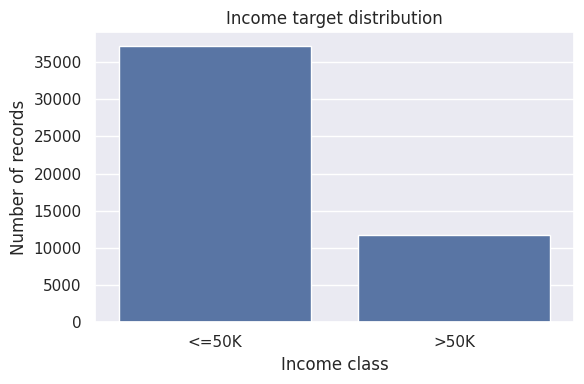

Numeric features (6): ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical features (8): ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


In [6]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y.map({0: "<=50K", 1: ">50K"}))
plt.title("Income target distribution")
plt.xlabel("Income class")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print(f"Numeric features ({len(numeric_features)}):", numeric_features)
print(f"Categorical features ({len(categorical_features)}):", categorical_features)

In [18]:
import numpy as np
import pandas as pd

# Clean the feature data
X = X.copy()

# Re-detect numeric and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Convert numeric columns to standard numeric types
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)

# Convert categorical columns to object dtype and replace missing values
for col in categorical_features:
    X[col] = X[col].astype(object)
    X[col] = X[col].where(pd.notna(X[col]), np.nan)

# Ensure target is a standard integer series
y = pd.to_numeric(y, errors="coerce")
valid = y.notna()

X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].astype("int64").reset_index(drop=True)

print("Feature data types:")
print(X.dtypes)
print("\nRemaining missing values:", int(X.isna().sum().sum()))
print("Missing target values:", int(y.isna().sum()))
print("Data cleaned successfully.")

Feature data types:
age               float64
workclass          object
fnlwgt            float64
education          object
education_num     float64
marital_status     object
occupation         object
relationship       object
race               object
sex                object
capital_gain      float64
capital_loss      float64
hours_per_week    float64
native_country     object
dtype: object

Remaining missing values: 6465
Missing target values: 0
Data cleaned successfully.


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("\nTest target proportions:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

Training feature shape: (39073, 14)
Test feature shape: (9769, 14)

Training target proportions:


,proportion
income,
0,0.76073
1,0.23927



Test target proportions:


,proportion
income,
0,0.760672
1,0.239328


In [20]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Handle numerical features
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="median",
        missing_values=np.nan
    )),
    ("scaler", StandardScaler())
])

# Handle categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        missing_values=np.nan
    )),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Create the complete ML model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Model and preprocessing pipeline created successfully.")

Model and preprocessing pipeline created successfully.


In [21]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

print("Preprocessing and classification pipeline created.")

Preprocessing and classification pipeline created.


In [22]:
X = X.copy()

for col in categorical_features:
    X[col] = X[col].astype(object)
    X[col] = X[col].where(pd.notna(X[col]), np.nan)

print("Missing target labels:", y.isna().sum())
print("Remaining pandas NA in features:", X.isna().sum().sum())
print("Data cleaning fix completed.")

Missing target labels: 0
Remaining pandas NA in features: 6465
Data cleaning fix completed.


In [23]:
model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


In [24]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (>50K)": precision_score(y_test, y_pred, zero_division=0),
    "Recall (>50K)": recall_score(y_test, y_pred, zero_division=0),
    "F1-score (>50K)": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
}

results_df = pd.DataFrame.from_dict(results, orient="index", columns=["Test score"])
display(results_df.style.format("{:.4f}"))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["<=50K", ">50K"],
    zero_division=0
))

,Test score
Accuracy,0.8507
Precision (>50K),0.7314
Recall (>50K),0.5941
F1-score (>50K),0.6557
ROC-AUC,0.9042



Classification report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      7431
        >50K       0.73      0.59      0.66      2338

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.84      0.85      0.85      9769



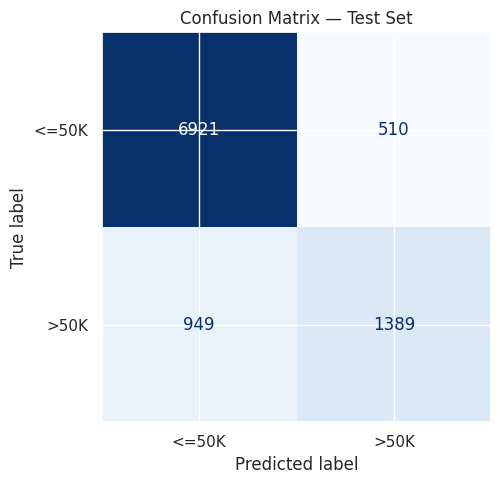

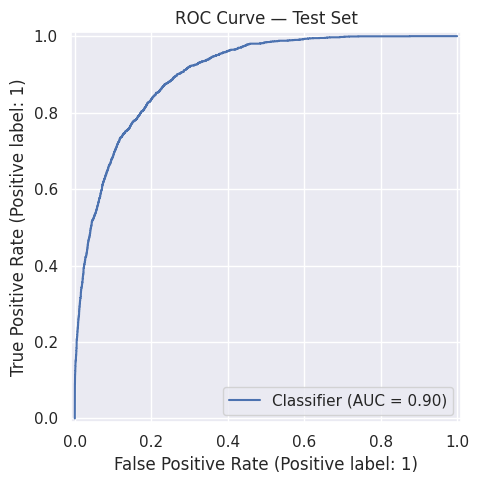

In [25]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["<=50K", ">50K"],
    cmap="Blues",
    ax=ax,
    colorbar=False
)
ax.set_title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax)
ax.set_title("ROC Curve — Test Set")
plt.tight_layout()
plt.show()

,feature,coefficient
3,numeric__capital_gain,2.290037
45,categorical__occupation_Priv-house-serv,-1.585996
98,categorical__native_country_South,-1.436488
32,categorical__marital_status_Married-civ-spouse,1.424114
31,categorical__marital_status_Married-AF-spouse,1.208172
67,categorical__native_country_Columbia,-1.182391
34,categorical__marital_status_Never-married,-1.117824
73,categorical__native_country_France,1.059564
54,categorical__relationship_Own-child,-1.003531
62,categorical__sex_Female,-0.923937


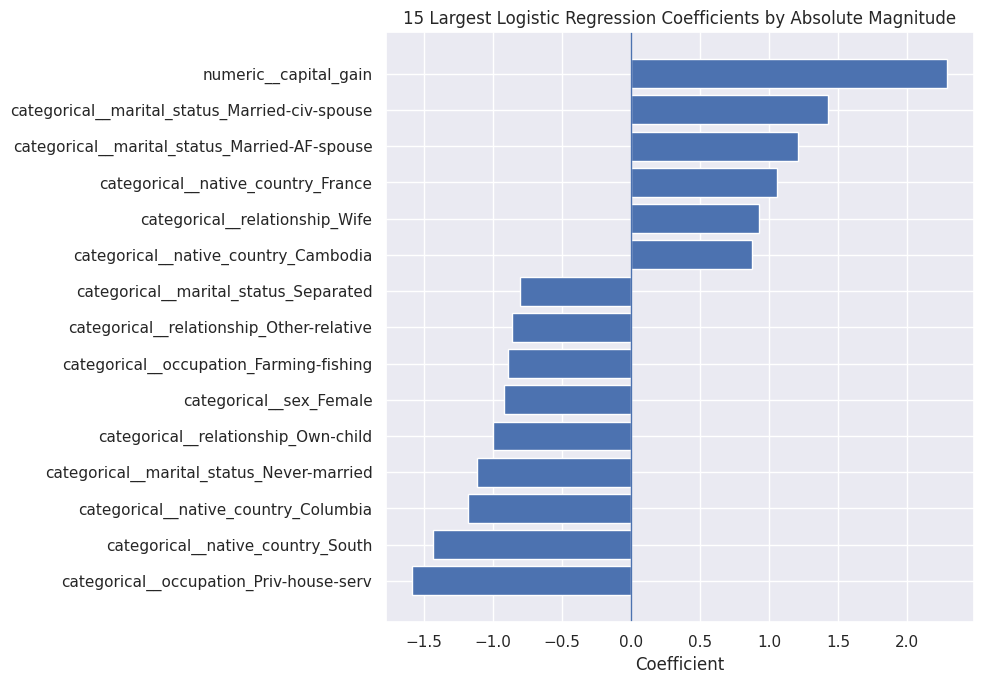

In [26]:
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

try:
    feature_names = fitted_preprocessor.get_feature_names_out()
    coefficients = fitted_classifier.coef_[0]
    coef_df = pd.DataFrame({
        "feature": feature_names,
        "coefficient": coefficients,
        "absolute_coefficient": np.abs(coefficients)
    }).sort_values("absolute_coefficient", ascending=False)

    display(coef_df.head(15)[["feature", "coefficient"]])

    top_coef = coef_df.head(15).sort_values("coefficient")
    plt.figure(figsize=(10, 7))
    plt.barh(top_coef["feature"], top_coef["coefficient"])
    plt.axvline(0, linewidth=1)
    plt.title("15 Largest Logistic Regression Coefficients by Absolute Magnitude")
    plt.xlabel("Coefficient")
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print("Coefficient inspection was not available in this environment:", exc)